# Phase 5 – Micron Sanand: analytics notebook

This notebook supports Section 6F of the India semiconductor case study. It has four parts:

- **A. Micron's memory cycle** – quarterly revenue and gross margin, FY2015–FY2026, and simple cycle statistics.
- **B. What management talks about** – how often India, Sanand, assembly/back-end and China come up on earnings calls, FY2023–FY2026.
- **C. Sanand 2030 throughput** – three hand-built scenarios, then a Monte Carlo simulation (10,000 runs) and a tornado chart.
- **D. What Sanand means for India** – value packaged in India, domestic value added, and depreciation per unit.

**Important rule:** Sanand is a captive Micron plant. Nothing here is Sanand revenue or profit. Part C estimates the *value of memory products that pass through* the plant, using normal-cycle (pre-2026-boom) prices.

All data files are in `data/`, each with a source column. Charts are saved to `charts/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

## A. Micron's memory cycle

Load the quarterly data. Revenue and gross margin are GAAP figures in US$ million from Micron's 10-K and 10-Q filings (via Bigdata.com). A few quarters are *derived* (for example, Q4 = annual total minus the first nine months); the `value_type` column says which.

In [2]:
q = pd.read_csv('../data/micron_quarterly.csv')
q['label'] = 'FY' + (q['fiscal_year'] % 100).astype(str).str.zfill(2) + ' Q' + q['fiscal_quarter'].astype(str)
q['gm_pct'] = 100 * q['gross_margin_usd_m'] / q['revenue_usd_m']
q[['label', 'revenue_usd_m', 'gross_margin_usd_m', 'gm_pct', 'value_type']].round(1).tail(10)

,label,revenue_usd_m,gross_margin_usd_m,gm_pct,value_type
38,FY24 Q3,6811,1832,26.9,Actual
39,FY24 Q4,7750,2737,35.3,Derived
40,FY25 Q1,8710,3350,38.5,Actual
41,FY25 Q2,8050,2960,36.8,Actual
42,FY25 Q3,9300,3510,37.7,Actual
43,FY25 Q4,11310,5050,44.7,Actual
44,FY26 Q1,13640,7650,56.1,Actual
45,FY26 Q2,23860,17750,74.4,Actual
46,FY26 Q3,41460,35060,84.6,Actual
47,FY26 Q4,54230,47050,86.8,Actual


Quick check: annual totals rebuilt from the quarters should match the 10-K figures (FY2023 gross margin about −9%, FY2026 revenue US$133.2B and gross margin about 81%).

In [3]:
annual = q.groupby('fiscal_year')[['revenue_usd_m', 'gross_margin_usd_m']].sum()
annual['gm_pct'] = 100 * annual['gross_margin_usd_m'] / annual['revenue_usd_m']
annual.round(1)

,revenue_usd_m,gross_margin_usd_m,gm_pct
fiscal_year,,,
2015,16192,5215,32.2
2016,12399,2505,20.2
2017,20322,8436,41.5
2018,30391,17891,58.9
2019,23406,10702,45.7
2020,21435,6552,30.6
2021,27705,10423,37.6
2022,30758,13898,45.2
2023,15540,-1416,-9.1


### Chart 1: revenue and gross margin

Bars show revenue; the line shows gross margin %. The pattern is the memory cycle: margins swing far more than revenue.

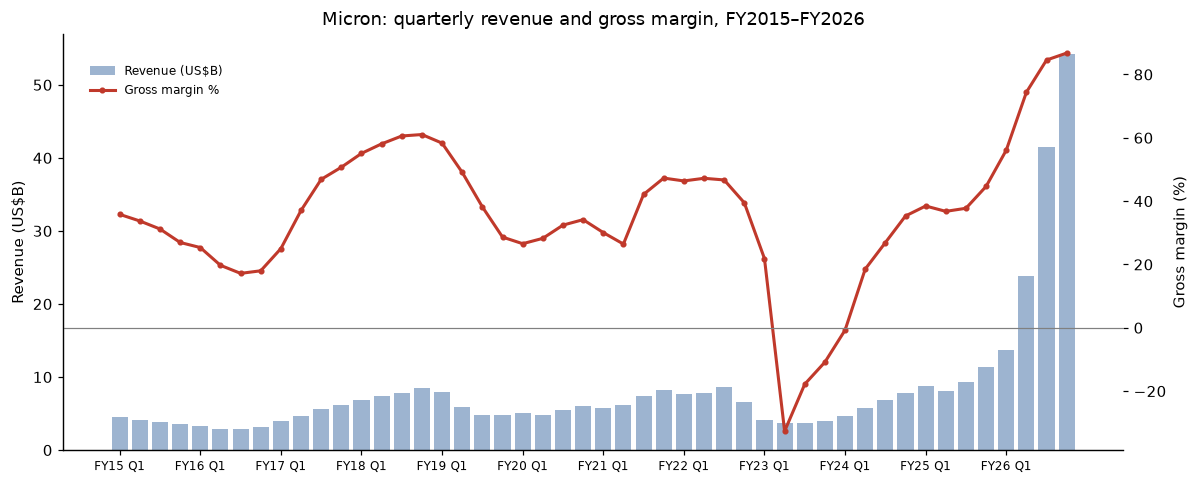

In [4]:
fig, ax1 = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(q))
ax1.bar(x, q['revenue_usd_m'] / 1000, color='#9db4d0', label='Revenue (US$B)')
ax1.set_ylabel('Revenue (US$B)')
ax2 = ax1.twinx()
ax2.plot(x, q['gm_pct'], color='#c0392b', lw=2, marker='o', ms=3, label='Gross margin %')
ax2.axhline(0, color='grey', lw=0.8)
ax2.set_ylabel('Gross margin (%)')
ticks = x[::4]
ax1.set_xticks(ticks)
ax1.set_xticklabels(q['label'].iloc[::4], rotation=0, fontsize=8)
ax1.set_title('Micron: quarterly revenue and gross margin, FY2015–FY2026')
fig.legend(loc='upper left', bbox_to_anchor=(0.07, 0.88), fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig('../charts/chart1_micron_revenue_gm.png', dpi=200)
plt.show()

### Cycle statistics

A simple rule for turning points: a quarter is a **peak** if its gross margin is the highest within three quarters on either side, and a **trough** if it is the lowest. Each peak is then paired with the next trough.

In [5]:
gm = q['gm_pct'].values
w = 3
turns = []
for i in range(len(gm)):
    window = gm[max(0, i - w): i + w + 1]
    if gm[i] == window.max():
        turns.append((i, 'peak'))
    elif gm[i] == window.min():
        turns.append((i, 'trough'))

rows = []
for (i, kind), (j, kind2) in zip(turns, turns[1:]):
    if kind == 'peak' and kind2 == 'trough':
        rows.append({'peak': q['label'][i], 'peak_gm_%': round(gm[i], 1),
                     'trough': q['label'][j], 'trough_gm_%': round(gm[j], 1),
                     'quarters_peak_to_trough': j - i,
                     'drop_in_pp': round(gm[i] - gm[j], 1)})
cycles = pd.DataFrame(rows)
cycles

,peak,peak_gm_%,trough,trough_gm_%,quarters_peak_to_trough,drop_in_pp
0,FY15 Q1,35.8,FY16 Q3,17.2,6,18.6
1,FY18 Q4,61.0,FY20 Q1,26.6,5,34.5
2,FY21 Q4,47.3,FY23 Q2,-32.7,6,79.9


In [6]:
print('Highest quarterly gross margin:', q.loc[q.gm_pct.idxmax(), 'label'], round(q.gm_pct.max(), 1), '%')
print('Lowest quarterly gross margin: ', q.loc[q.gm_pct.idxmin(), 'label'], round(q.gm_pct.min(), 1), '%')
print('Average peak-to-trough length:', cycles['quarters_peak_to_trough'].mean().round(1), 'quarters')

Highest quarterly gross margin: FY26 Q4 86.8 %
Lowest quarterly gross margin:  FY23 Q2 -32.7 %
Average peak-to-trough length: 5.7 quarters


### Capex as % of revenue at peaks vs troughs

Quarterly capex is only available here for FY2025–FY2026, so I add the few annual figures I could source. These are mixed bases (gross vs net of incentives), so read them as rough.

In [7]:
capex_annual = pd.DataFrame({
    'fiscal_year': [2016, 2024, 2025, 2026],
    'capex_usd_b': [5.40, 8.0, 13.8, 27.4],
    'revenue_usd_b': [12.399, 25.111, 37.378, 133.188],
    'cycle_phase': ['trough year', 'recovery', 'upturn', 'boom peak'],
    'source': ['FY2016 10-K (net of partner funding)',
               'FQ3-24 call: "approximately $8 billion" (guide, estimate)',
               'Phase 1 summary (Micron 10-K, net)', 'Phase 1 summary (Micron 10-K, net)']})
capex_annual['capex_%_revenue'] = (100 * capex_annual['capex_usd_b'] / capex_annual['revenue_usd_b']).round(1)
capex_annual

,fiscal_year,capex_usd_b,revenue_usd_b,cycle_phase,source,capex_%_revenue
0,2016,5.4,12.399,trough year,FY2016 10-K (net of partner funding),43.6
1,2024,8.0,25.111,recovery,"FQ3-24 call: ""approximately $8 billion"" (guide...",31.9
2,2025,13.8,37.378,upturn,"Phase 1 summary (Micron 10-K, net)",36.9
3,2026,27.4,133.188,boom peak,"Phase 1 summary (Micron 10-K, net)",20.6


In [8]:
recent = q[q['capex_gross_usd_m'].notna()].copy()
recent['capex_%_revenue'] = (100 * recent['capex_gross_usd_m'] / recent['revenue_usd_m']).round(1)
recent[['label', 'gm_pct', 'capex_%_revenue', 'inventory_usd_m']].round(1)

,label,gm_pct,capex_%_revenue,inventory_usd_m
40,FY25 Q1,38.5,36.9,8710.0
41,FY25 Q2,36.8,50.3,9010.0
42,FY25 Q3,37.7,31.6,8730.0
43,FY25 Q4,44.7,50.0,8360.0
44,FY26 Q1,56.1,39.5,8210.0
45,FY26 Q2,74.4,26.8,8270.0
46,FY26 Q3,84.6,18.9,8570.0
47,FY26 Q4,86.8,20.5,10370.0


**What this shows:** in the trough year (FY2016) capex was ~44% of a shrunken revenue base; at the FY2026 peak it was ~21–23% of a revenue base that had quadrupled. Capex in dollars rises in a boom, but revenue rises faster. Capex intensity is high when margins are low, because fabs must keep investing through the downturn.

## B. What management talks about on earnings calls

Method: Bigdata.com keyword search over Micron's earnings-call transcripts (prepared remarks, Q&A and the post-earnings analyst call). Each number is the count of **transcript passages** that mention the term. Where two transcript copies exist, I use the larger count. Back-end passages are counted only when they mean manufacturing (not phrases like "back-end loaded"). China includes "CAC" and "Xi'an".

In [9]:
m = pd.read_csv('../data/call_mentions.csv')
m['label'] = 'FY' + (m['fiscal_year'] % 100).astype(str) + ' Q' + m['fiscal_quarter'].astype(str)
m[['label', 'call_date', 'india', 'sanand', 'assembly_backend', 'china']]

,label,call_date,india,sanand,assembly_backend,china
0,FY23 Q1,2022-12-21,0,0,5,10
1,FY23 Q2,2023-03-28,0,0,1,6
2,FY23 Q3,2023-06-28,1,0,4,18
3,FY23 Q4,2023-09-27,0,0,3,10
4,FY24 Q1,2023-12-20,0,0,3,3
5,FY24 Q2,2024-03-20,1,0,7,1
6,FY24 Q3,2024-06-26,0,0,2,0
7,FY24 Q4,2024-09-25,1,0,6,4
8,FY25 Q1,2024-12-18,1,0,2,6
9,FY25 Q2,2025-03-20,0,0,3,4


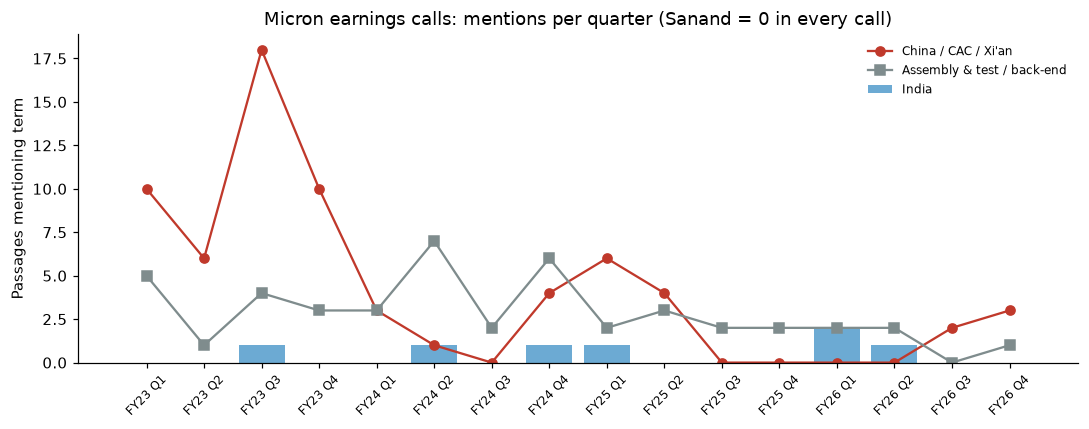

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
xx = np.arange(len(m))
ax.plot(xx, m['china'], marker='o', color='#c0392b', label='China / CAC / Xi\'an')
ax.plot(xx, m['assembly_backend'], marker='s', color='#7f8c8d', label='Assembly & test / back-end')
ax.bar(xx, m['india'], color='#2e86c1', alpha=0.7, label='India')
ax.set_xticks(xx)
ax.set_xticklabels(m['label'], rotation=45, fontsize=8)
ax.set_ylabel('Passages mentioning term')
ax.set_title('Micron earnings calls: mentions per quarter (Sanand = 0 in every call)')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig('../charts/chart2_call_mentions.png', dpi=200)
plt.show()

In [11]:
print('Total passages FY23-FY26 ->', m[['india', 'sanand', 'assembly_backend', 'china']].sum().to_dict())
print('China passages FY23 vs FY26:', m.loc[m.fiscal_year == 2023, 'china'].sum(), 'vs', m.loc[m.fiscal_year == 2026, 'china'].sum())

Total passages FY23-FY26 -> {'india': 7, 'sanand': 0, 'assembly_backend': 45, 'china': 67}
China passages FY23 vs FY26: 44 vs 5


**Quotes that show the shift** (short extracts, Micron earnings calls via Bigdata.com):

1. 28 Jun 2023 (FQ3-23): India facility is "to address demand for the latter half of this decade."
2. 20 Mar 2024 (FQ2-24): planning capacity "to ensure a diversified and cost competitive manufacturing footprint."
3. 25 Sep 2024 (FQ4-24): "Construction is underway on our India assembly and test facility"
4. 17 Dec 2025 (FQ1-26): the India site "has initiated pilot production and will ramp in 2026."
5. 18 Mar 2026 (FQ2-26): "we commenced commercial shipments from our new facility in India."

On China: Micron's 8-K of 16 Jun 2023 said a "low-double-digit percentage" of worldwide revenue was at risk; by the FQ4-26 analyst call (30 Sep 2026), management expected China exposure "in the single-digit range in fiscal 2027."

**What this shows:** China was the dominant theme in FY2023 (the CAC ban). India appears in about one call in two, always in one line of the capacity update, and "Sanand" is never named. For Micron, India is an operations item, not a strategy headline.

## C. Sanand 2030 throughput: scenarios and Monte Carlo

### Inputs

Each input has a low, most-likely (mode) and high value, with its basis. Prices are **normal-cycle** (late 2024 to mid 2025), not 2026 boom prices: TrendForce's 2026 outlooks imply DRAM contract prices about 6x and NAND about 4x their late-2025 levels by end-2026.

In [12]:
inp = pd.read_csv('../data/sanand_inputs.csv').set_index('input')
inp[['low', 'mode', 'high', 'unit', 'type']]

,low,mode,high,unit,type
input,,,,,
capacity_units,1352.000,1352.00,1352.00,million packaged units per year,Actual (as stated)
utilisation_2030,0.300,0.55,0.85,share of 1352M,Assumed
dram_share_units,0.500,0.65,0.80,share of units,Assumed
ssd_share_units,0.005,0.01,0.02,share of units,Assumed
dram_value_per_chip_usd,2.500,4.00,6.00,US$ per packaged DRAM chip,Assumed (anchored)
nand_value_per_package_usd,4.000,9.00,18.00,US$ per packaged NAND component,Assumed (anchored)
ssd_value_per_unit_usd,35.000,60.00,110.00,US$ per SSD,Assumed (anchored)
domestic_share_of_output,0.100,0.20,0.30,share of Sanand output sold in India,Assumed
india_value_added_share,0.100,0.12,0.15,back-end share of product value,Assumed


In [13]:
# The 2026 boom check: compound the TrendForce quarterly contract-price midpoints (P5 files)
dram = (1.475) * (1.955) * (1.605) * (1.155) * (1.125)   # 4Q25 +45-50%, 1Q26 +93-98%, 2Q26 +58-63%, 3Q26 +13-18%, 4Q26 +10-15%
nand = (1.875) * (1.725) * (1.125) * (1.175)              # 1Q26 +85-90%, 2Q26 +70-75%, 3Q26 +10-15%, 4Q26 +15-20%
print(f'Conventional DRAM contract price, end-2026 vs 3Q25: ~{dram:.1f}x')
print(f'NAND contract price, end-2026 vs 4Q25: ~{nand:.1f}x')

Conventional DRAM contract price, end-2026 vs 3Q25: ~6.0x
NAND contract price, end-2026 vs 4Q25: ~4.3x


### Value per unit

Each Sanand "unit" is a packaged chip (DRAM or NAND) or a finished SSD. An SSD's NAND chips are counted inside the SSD, not again as NAND chips. Value per unit is a weighted average:

`value per unit = DRAM share × DRAM price + NAND share × NAND price + SSD share × SSD price`, where NAND share = 1 − DRAM share − SSD share.

In [14]:
CAP = inp.loc['capacity_units', 'mode']   # million units per year

def value_per_unit(dram_share, ssd_share, p_dram, p_nand, p_ssd):
    nand_share = 1 - dram_share - ssd_share
    return dram_share * p_dram + nand_share * p_nand + ssd_share * p_ssd

scen = {
    'Conservative': dict(util2030=0.35, ramp=[0.015, 0.11, 0.20, 0.28, 0.35], dram=0.70, ssd=0.005, p_dram=3.0, p_nand=6.0, p_ssd=40),
    'Base':         dict(util2030=0.55, ramp=[0.03, 0.18, 0.33, 0.45, 0.55], dram=0.65, ssd=0.010, p_dram=4.0, p_nand=9.0, p_ssd=60),
    'Optimistic':   dict(util2030=0.80, ramp=[0.05, 0.30, 0.45, 0.62, 0.80], dram=0.60, ssd=0.015, p_dram=5.0, p_nand=12.0, p_ssd=80),
}
years = [2026, 2027, 2028, 2029, 2030]
rows = []
for name, s in scen.items():
    vpu = value_per_unit(s['dram'], s['ssd'], s['p_dram'], s['p_nand'], s['p_ssd'])
    for y, u in zip(years, s['ramp']):
        units = u * CAP
        rows.append({'scenario': name, 'year': y, 'utilisation_%': round(100 * u, 1),
                     'units_m': round(units), 'value_per_unit_usd': round(vpu, 2),
                     'throughput_value_usd_b': round(units * vpu / 1000, 2)})
ramp = pd.DataFrame(rows)
ramp.pivot(index='year', columns='scenario', values='units_m')

scenario,Base,Conservative,Optimistic
year,,,
2026,41,20,68
2027,243,149,406
2028,446,270,608
2029,608,379,838
2030,744,473,1082


In [15]:
ramp.pivot(index='year', columns='scenario', values='throughput_value_usd_b')

scenario,Base,Conservative,Optimistic
year,,,
2026,0.25,0.08,0.60
2027,1.52,0.61,3.58
2028,2.79,1.10,5.37
2029,3.81,1.54,7.39
2030,4.65,1.93,9.54


Check against Micron's own words: "tens of millions" of chips in 2026 (20–68M here) and "hundreds of millions" in 2027 (149–406M here). Phase 1 alone is about 728M units a year (PIB, ~14M a week), so the base case in 2030 (744M) is roughly Phase 1 running full.

### Monte Carlo: 10,000 runs

Each input is drawn from a triangular distribution (low, mode, high). A triangular distribution is the simplest way to say "most likely X, but could be anywhere from L to H". If a draw makes DRAM share + SSD share above 100% (it cannot happen with these ranges), the NAND share would go negative, so I check for it.

In [16]:
rng = np.random.default_rng(42)
N = 10_000
def tri(name):
    r = inp.loc[name]
    return rng.triangular(r['low'], r['mode'], r['high'], N)

util = tri('utilisation_2030')
dram_s = tri('dram_share_units')
ssd_s = tri('ssd_share_units')
p_dram = tri('dram_value_per_chip_usd')
p_nand = tri('nand_value_per_package_usd')
p_ssd = tri('ssd_value_per_unit_usd')

assert (dram_s + ssd_s < 1).all()
units = util * CAP                                    # million units
vpu = value_per_unit(dram_s, ssd_s, p_dram, p_nand, p_ssd)
value_b = units * vpu / 1000                          # US$ billion

summary = pd.DataFrame({
    'units_m': np.percentile(units, [10, 50, 90]),
    'value_per_unit_usd': np.percentile(vpu, [10, 50, 90]),
    'throughput_value_usd_b': np.percentile(value_b, [10, 50, 90])},
    index=['P10', 'P50', 'P90']).round(2)
summary

,units_m,value_per_unit_usd,throughput_value_usd_b
P10,565.40,5.54,3.61
P50,760.21,6.89,5.23
P90,973.25,8.60,7.28


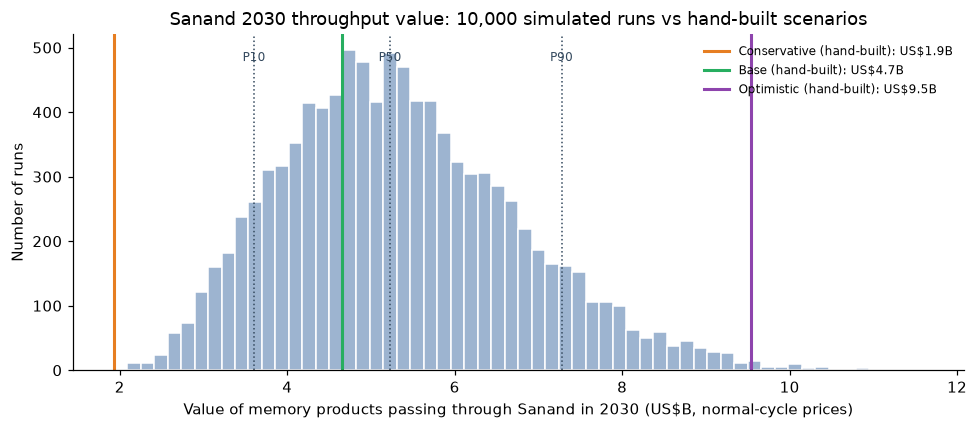

In [17]:
hand = ramp[ramp.year == 2030].set_index('scenario')['throughput_value_usd_b']
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(value_b, bins=60, color='#9db4d0', edgecolor='white')
for p, lab in zip(np.percentile(value_b, [10, 50, 90]), ['P10', 'P50', 'P90']):
    ax.axvline(p, color='#34495e', ls=':', lw=1)
    ax.text(p, ax.get_ylim()[1] * 0.92, lab, ha='center', fontsize=8, color='#34495e')
colors = {'Conservative': '#e67e22', 'Base': '#27ae60', 'Optimistic': '#8e44ad'}
for name, v in hand.items():
    ax.axvline(v, color=colors[name], lw=2, label=f'{name} (hand-built): US${v:.1f}B')
ax.set_xlabel('Value of memory products passing through Sanand in 2030 (US$B, normal-cycle prices)')
ax.set_ylabel('Number of runs')
ax.set_title('Sanand 2030 throughput value: 10,000 simulated runs vs hand-built scenarios')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig('../charts/chart3_montecarlo_2030.png', dpi=200)
plt.show()

### Tornado chart: which input matters most?

Hold every input at its mode, then move one input to its low and high value and record the 2030 throughput value. The longest bar is the input that matters most.

In [18]:
base_inputs = {k: inp.loc[k, 'mode'] for k in ['utilisation_2030', 'dram_share_units', 'ssd_share_units',
                                               'dram_value_per_chip_usd', 'nand_value_per_package_usd', 'ssd_value_per_unit_usd']}
def model(d):
    v = value_per_unit(d['dram_share_units'], d['ssd_share_units'], d['dram_value_per_chip_usd'],
                       d['nand_value_per_package_usd'], d['ssd_value_per_unit_usd'])
    return d['utilisation_2030'] * CAP * v / 1000

base_val = model(base_inputs)
rows = []
for k in base_inputs:
    lo = dict(base_inputs); lo[k] = inp.loc[k, 'low']
    hi = dict(base_inputs); hi[k] = inp.loc[k, 'high']
    rows.append({'input': k, 'low_case': model(lo), 'high_case': model(hi)})
tor = pd.DataFrame(rows)
tor['swing'] = (tor['high_case'] - tor['low_case']).abs()
tor = tor.sort_values('swing')
print(f'Base (all inputs at mode): US${base_val:.2f}B')
tor.round(2)

Base (all inputs at mode): US$4.65B


,input,low_case,high_case,swing
5,ssd_value_per_unit_usd,4.47,5.03,0.56
2,ssd_share_units,4.47,5.03,0.57
1,dram_share_units,5.21,4.10,1.12
3,dram_value_per_chip_usd,3.93,5.62,1.69
4,nand_value_per_package_usd,3.39,6.93,3.54
0,utilisation_2030,2.54,7.19,4.65


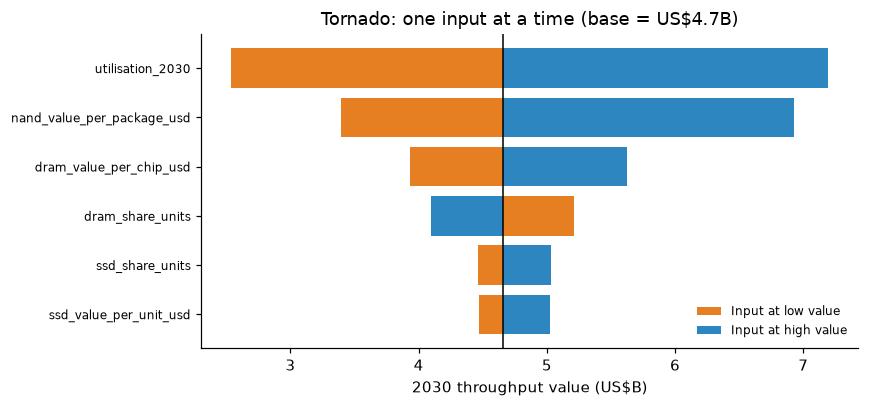

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.8))
yy = np.arange(len(tor))
ax.barh(yy, tor['low_case'] - base_val, left=base_val, color='#e67e22', label='Input at low value')
ax.barh(yy, tor['high_case'] - base_val, left=base_val, color='#2e86c1', label='Input at high value')
ax.axvline(base_val, color='black', lw=1)
ax.set_yticks(yy)
ax.set_yticklabels(tor['input'], fontsize=8)
ax.set_xlabel('2030 throughput value (US$B)')
ax.set_title(f'Tornado: one input at a time (base = US${base_val:.1f}B)')
ax.legend(frameon=False, fontsize=8, loc='lower right')
fig.tight_layout()
fig.savefig('../charts/chart4_tornado.png', dpi=200)
plt.show()

**What this shows:** utilisation (how fast Phase 1 fills and whether Phase 2 arrives) and the NAND price per package swing the answer most. The DRAM/NAND mix matters because a NAND package carries more value than a DRAM chip. The SSD assumptions barely matter.

## D. What Sanand means for India

### Value packaged in India vs India's market

India's 2030 chip market (base case, Phase 2) is US$96B. Two caveats: (1) Sanand's throughput value includes the imported wafer (the die), so it is a *gross* value; (2) most of it is exported.

In [20]:
INDIA_MKT_2030 = 96.0   # US$B, Phase 2 base case (IESA consumption series)
dom = inp.loc['domestic_share_of_output']
va = inp.loc['india_value_added_share']
out = []
for name in ['Conservative', 'Base', 'Optimistic']:
    v = hand[name]
    out.append({'scenario': name, 'throughput_usd_b': v,
                'as_%_of_india_market (gross)': round(100 * v / INDIA_MKT_2030, 1),
                'sold_in_india_usd_b (20%)': round(v * dom['mode'], 2),
                'sold_in_india_%_of_market': round(100 * v * dom['mode'] / INDIA_MKT_2030, 1),
                'value_added_in_india_usd_b (12%)': round(v * va['mode'], 2),
                'value_added_%_of_market': round(100 * v * va['mode'] / INDIA_MKT_2030, 2)})
india = pd.DataFrame(out)
india

,scenario,throughput_usd_b,as_%_of_india_market (gross),sold_in_india_usd_b (20%),sold_in_india_%_of_market,value_added_in_india_usd_b (12%),value_added_%_of_market
0,Conservative,1.93,2.0,0.39,0.4,0.23,0.24
1,Base,4.65,4.8,0.93,1.0,0.56,0.58
2,Optimistic,9.54,9.9,1.91,2.0,1.14,1.19


**Reading this:** in the base case, chips worth about 5% of India's market value pass through Sanand, but only about 1% of India's market is supplied from Sanand to Indian buyers, and India adds about 0.6% of market value. So Sanand raises the share of chips *physically packaged* in India but barely lowers *import dependence*.

### Capex and depreciation per unit (illustrative, not company accounts)

Total project cost ₹22,516 crore (both phases), capacity 1,352M units a year, straight-line over 7 years (the OSAT life used in Phase 3). With 70% government support (50% centre + 20% Gujarat), Micron's own depreciable cost is 30%.

In [21]:
PROJECT_CR = 22516            # Rs crore, Micron disclosure (US$2.75B at Rs82)
FX_2023, FX_2026 = 82, 95
LIFE = 7
cap_units = CAP * 1e6
rs_per_unit_capacity = PROJECT_CR * 1e7 / cap_units
print(f'Capex per unit of annual capacity: Rs {rs_per_unit_capacity:.0f} gross (US${rs_per_unit_capacity/FX_2023:.2f} at Rs{FX_2023})')
print(f'  Micron share (30%): Rs {0.30*rs_per_unit_capacity:.0f}; in present-value terms (~35%): Rs {0.35*rs_per_unit_capacity:.0f}')

rows = []
for label, units_m in [('Full capacity', CAP), ('Base 2030 (55%)', 0.55 * CAP)]:
    for support in [0.0, 0.70]:
        dep_rs = PROJECT_CR * 1e7 * (1 - support) / LIFE / (units_m * 1e6)
        rows.append({'volume': label, 'support': f'{int(support*100)}%',
                     'depreciation_rs_per_unit': round(dep_rs, 1),
                     'depreciation_usd_per_unit': round(dep_rs / FX_2026, 3),
                     '%_of_base_value_per_unit': round(100 * dep_rs / FX_2026 / value_per_unit(0.65, 0.01, 4, 9, 60), 1)})
pd.DataFrame(rows)

Capex per unit of annual capacity: Rs 167 gross (US$2.03 at Rs82)
  Micron share (30%): Rs 50; in present-value terms (~35%): Rs 58


,volume,support,depreciation_rs_per_unit,depreciation_usd_per_unit,%_of_base_value_per_unit
0,Full capacity,0%,23.8,0.250,4.0
1,Full capacity,70%,7.1,0.075,1.2
2,Base 2030 (55%),0%,43.3,0.455,7.3
3,Base 2030 (55%),70%,13.0,0.137,2.2


**Reading this:** back-end depreciation is a small slice of a memory product's value: a few percent without support and about 1–2% with it. So for Micron the subsidy matters mainly as a cash saving on a US$2.75B build (Micron pays about US$825M), not because it changes the cost of a memory chip much. The labour gap (JETRO: India US$294 vs Malaysia US$403 vs China US$510 a month) is similar in size.

### Save the scenario table for the Excel "Financial scenarios" tab

In [22]:
ramp.to_csv('../data/sanand_scenarios_2026_2030.csv', index=False)
summary.to_csv('../data/sanand_montecarlo_summary.csv')
tor.round(3).to_csv('../data/sanand_tornado.csv', index=False)
print('saved')

saved
